# Part 2 of the Journey! Classification! Let's get started!



Many times, in ML, we are often faced with classification problems. Sorting, and so on. An example is a bot that selects SPam email or not SPAM. This is called Binary Classificaiton. There is also multiclass CLassificaiton where there are several options. Note: All options here have a clear label. In label classification, there are multiple label options per sample.

#  Make classification Data.


In [ ]:
import sklearn

In [ ]:
from sklearn.datasets import make_circles
n_samples = 1000
X, y = make_circles(n_samples, noise=0.03, random_state=42)

In [ ]:
len(X), len(y)

(1000, 1000)

In [ ]:
X[:5], y[:5]


(array([[ 0.75424625,  0.23148074],
        [-0.75615888,  0.15325888],
        [-0.81539193,  0.17328203],
        [-0.39373073,  0.69288277],
        [ 0.44220765, -0.89672343]]),
 array([1, 1, 1, 1, 0]))

In [ ]:
import pandas as pd
circles = pd.DataFrame({'X1':X[:,0], 'X2':X[:,1], 'label':y})
circles

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
...,...,...,...
995,0.244054,0.944125,0
996,-0.978655,-0.272373,0
997,-0.136900,-0.810012,1
998,0.670362,-0.767502,0


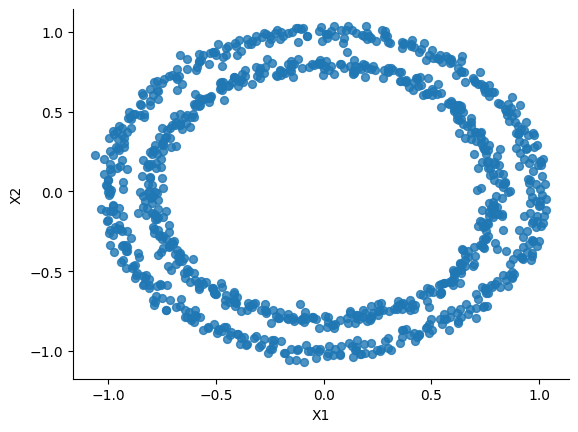

In [ ]:
from matplotlib import pyplot as plt
circles.plot(kind='scatter', x='X1', y='X2', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
X.shape, y.shape

((1000, 2), (1000,))

In [ ]:
X

array([[ 0.75424625,  0.23148074],
       [-0.75615888,  0.15325888],
       [-0.81539193,  0.17328203],
       ...,
       [-0.13690036, -0.81001183],
       [ 0.67036156, -0.76750154],
       [ 0.28105665,  0.96382443]])

In [ ]:
# View the first example of features and labels
x_sample = X[0]
y_sample = y[0]
print(f'Sample input of features: {x_sample}')
print(f'Sample label: {y_sample}')

Sample input of features: [0.75424625 0.23148074]
Sample label: 1


In [ ]:
# 1.2 Turning data into tensors, and test splits


type(X), X.dtype, type(y), y.dtype

(numpy.ndarray, dtype('float64'), numpy.ndarray, dtype('int64'))

In [ ]:
import torch

X= torch.from_numpy(X).type(torch.float)
y= torch.from_numpy(y).type(torch.float)

X[:5], y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [ ]:
# Split data into training and  tests sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Let's Build a model to classify our blue and red dots (Inner and outer circle)
We need to:
1. Setup device agonisitc code
2. Construct a model
3. Define loss function
4. Test loop



In [ ]:
import torch
from torch import nn

# Make device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Now that we have set up agnostic code, let's work with 2:
1. SUbclass  `nn.Module`
2. Create 2 nn.Linear() => layers that  are capable of handling the shapes of our data
3. Defines a forward() method that outlines the forward pass
3. Instatiate an instance of our model class and send it to the target device

In [ ]:
class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()
    # 2. Create 2 nn.Linear layers capablr of handling shapes of our data:
    self.layer_1 = nn.Linear(in_features= 2, out_features=5)
    self.layer_2 = nn.Linear(in_features=5, out_features=1)

  def forward(self, x):
    return self.layer_2(self.layer_1(x)) # x -> L1 -> L2 -> Output
    # Instantiate an instance of our model
model_0 = CircleModelV0().to(device)
model_0

CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [ ]:
device

'cuda'

In [ ]:
next(model_0.parameters()).device

device(type='cuda', index=0)

In [ ]:
model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
).to(device)
# An easier way of doing what we just did. However, when working with more complex models, it is important to know how to work with the steps yourself.

model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [ ]:
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[ 0.3198, -0.2488],
                      [ 0.5505, -0.5207],
                      [ 0.4772,  0.0884],
                      [-0.1219,  0.5120],
                      [-0.3121,  0.1180]], device='cuda:0')),
             ('0.bias',
              tensor([-0.2422,  0.2507,  0.2893,  0.5950, -0.3765], device='cuda:0')),
             ('1.weight',
              tensor([[ 0.1124, -0.0336,  0.3269, -0.2957, -0.1535]], device='cuda:0')),
             ('1.bias', tensor([0.3277], device='cuda:0'))])

In [ ]:
# Make predictions with the model
untrained_preds = model_0(X_test.to(device))
print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test samples: {len(y_test)}, Shape: {y_test.shape}")
print(f"\nFirst 10 predictions:\n{untrained_preds[:10]}")
print(f"\nFirst 10 test labels:\n{y_test[:10]}")

Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test samples: 200, Shape: torch.Size([200])

First 10 predictions:
tensor([[0.0688],
        [0.1275],
        [0.1351],
        [0.0491],
        [0.4844],
        [0.5175],
        [0.4058],
        [0.4980],
        [0.1203],
        [0.1352]], device='cuda:0', grad_fn=<SliceBackward0>)

First 10 test labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [ ]:
y_test[:10], X_test[:10]

(tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.]),
 tensor([[-0.3752,  0.6827],
         [ 0.0154,  0.9600],
         [-0.7028, -0.3147],
         [-0.2853,  0.9664],
         [ 0.4024, -0.7438],
         [ 0.6323, -0.5711],
         [ 0.8561,  0.5499],
         [ 1.0034,  0.1903],
         [-0.7489, -0.2951],
         [ 0.0538,  0.9739]]))

#  Setup loss function and optimizer
We've setup a loss (also called a criterion or cost function) and optimizer before in notebook 01.


But different problem types require different loss functions.
For example, for a regression problem (predicting a number) you might use mean absolute error (MAE) loss.
And for a binary classification problem (like ours), you'll often use binary cross entropy as the loss function.


However, the same optimizer function can often be used across different problem spaces.
For example, the stochastic gradient descent optimizer (SGD, torch.optim.SGD()) can be used for a range of problems, and the same applies to the Adam optimizer (torch.optim.Adam()).

In [ ]:
# Set up loss function and optimizer
# Which loss function or optimiser should you use? =>
# Problem specific| For classfication, you would want cross Entropy and MSE for linear regression

# Set up the loss function
loss_fn = nn.BCEWithLogitsLoss()

# Set up the optimizer
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

In [ ]:
# Calculating accuracy in (%)
def accuracy_fn(y_true, y_pred):
  correct = torch.eq(y_true, y_pred).sum().item()
  acc = (correct / len(y_pred)) * 100
  return acc

#  Going from raw model outputs to predicted labels (logits -> prediction probabilities -> prediction labels)

Our model outputs are going t be raw `Logits`.
We can convert these logits into prediction probablities by passing them to some kinf of activation function.

In [ ]:
# Building training loop
model_0.eval()
with torch.inference_mode():
  y_logits = model_0(X_test.to(device))[:5]
y_logits


tensor([[0.0688],
        [0.1275],
        [0.1351],
        [0.0491],
        [0.4844]], device='cuda:0')

In [ ]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

In [ ]:
y_pred_probs = torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.5172],
        [0.5318],
        [0.5337],
        [0.5123],
        [0.6188]], device='cuda:0')

For our prediction probability values, we need to perform a range-style round on them:
`y_pred_probs` >= 0.5, y=1 (class 1)
`y_pred_probs` <= 0.5, y=0 (class 0)


In [ ]:
torch.round(y_pred_probs)

tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.]], device='cuda:0')

In [ ]:
# Find the predicted labels (round the prediction probabilities)
y_pred_probs = torch.sigmoid(model_0(X_test.to(device))[:5])
y_preds = torch.round(y_pred_probs)

# In full
y_pred_labels = torch.round(torch.sigmoid(model_0(X_test.to(device))[:5]))

# Check for equality
print(torch.eq(y_preds.squeeze(), y_pred_labels.squeeze()))

# Get rid of extra dimension
y_preds.squeeze()

tensor([True, True, True, True, True], device='cuda:0')


tensor([1., 1., 1., 1., 1.], device='cuda:0', grad_fn=<SqueezeBackward0>)

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

#Set number of Epoch
epochs = 100

#Put data on target device
X_train, y_train, X_test, y_test = X_train.to(device), y_train.to(device), X_test.to(device), y_test.to(device)

# Building training and evaluation loop
for epoch in range(epochs):
  ### Training
  model_0.train()

  # 1. Forward pass
  y_logits = model_0(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

# Calc accuracy
  loss = loss_fn(y_logits, y_train) #nn.BCEWithLogitsLoss/// expects raw logits as input
  acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

  # Note that the order above is important.

  # Optimizer zero grad
  optimizer.zero_grad()

  # Loss backward
  loss.backward()

  # Optimizer step (backpropagation)
  optimizer.step()

  # Testing (gradient descent)
  model_0.eval()
  with torch.inference_mode():
    test_logits = model_0(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))

    # Calculate test loss/ acc
    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

  if epoch % 10 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.70704, Accuracy: 56.88% | Test Loss: 0.70423, Test Acc: 58.00%
Epoch: 10 | Loss: 0.70013, Accuracy: 53.37% | Test Loss: 0.69816, Test Acc: 55.50%
Epoch: 20 | Loss: 0.69710, Accuracy: 51.38% | Test Loss: 0.69563, Test Acc: 55.00%
Epoch: 30 | Loss: 0.69564, Accuracy: 50.75% | Test Loss: 0.69451, Test Acc: 54.00%
Epoch: 40 | Loss: 0.69484, Accuracy: 49.62% | Test Loss: 0.69398, Test Acc: 54.00%
Epoch: 50 | Loss: 0.69434, Accuracy: 49.88% | Test Loss: 0.69372, Test Acc: 53.50%
Epoch: 60 | Loss: 0.69401, Accuracy: 50.25% | Test Loss: 0.69359, Test Acc: 51.00%
Epoch: 70 | Loss: 0.69377, Accuracy: 50.12% | Test Loss: 0.69353, Test Acc: 51.00%
Epoch: 80 | Loss: 0.69359, Accuracy: 49.62% | Test Loss: 0.69351, Test Acc: 49.50%
Epoch: 90 | Loss: 0.69346, Accuracy: 49.62% | Test Loss: 0.69352, Test Acc: 51.50%


As we can see, it is pretty much just as good as guessing.

In [ ]:
import requests
from pathlib import Path

# Download helper functions from Learn Python repo
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary



helper_functions.py already exists, skipping download


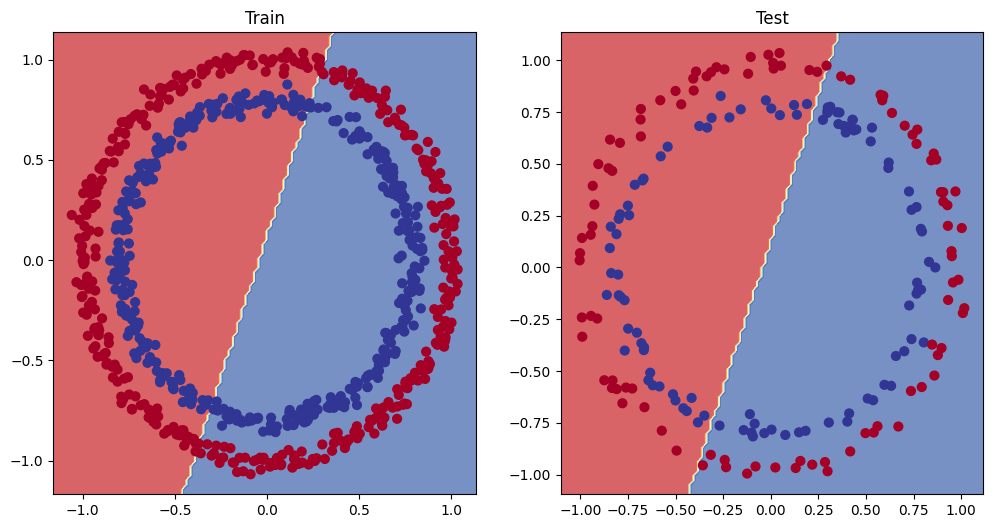

In [ ]:
# Plot decision boundary of the model
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)


# How could be make the model better?
# - Add more layers
# - Add more hidden units, go from 5 to 10 perhaps
# - Fit for longer
# - change the learning rate
# - Change optimization and loss function

# Our model is trying to draw 1 straight line to split the datasets, which might now work great in this scenario..... What do we do?

In [ ]:
# Let's work with improving accuracy
class CircleModelV1(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1 = nn.Linear(in_features=2, out_features=10)
    self.layer_2 = nn.Linear(in_features=10, out_features=10)
    self.layer_3 = nn.Linear(in_features=10, out_features=1)

  def forward(self, x):
    return self.layer_3(self.layer_2(self.layer_1(x)))

model_1 = CircleModelV1().to(device)
model_1

CircleModelV1(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [ ]:
# Create a loss function
loss_fn = nn.BCEWithLogitsLoss()

# Create an optimizer
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

# The reason it becomes more accurate when add more layers is beacuse deeper networks can learn more complex patterns and representations in the data.

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# Train for longer
epochs = 1000

# Put the data on the target device
X_train, y_train, X_test, y_test = X_train.to(device), y_train.to(device), X_test.to(device), y_test.to(device)

for epoch in range(epochs):
  model_1.train()
  y_logits = model_1(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  # Calc accuracy
  loss = loss_fn(y_logits, y_train) # Use y_train for training loss
  acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

  # Optimizer zero grad
  optimizer.zero_grad()
  # Loss backward
  loss.backward()
  # Optimizer step (backpropagation)
  optimizer.step()

  # Testing
  model_1.eval()
  with torch.inference_mode():
    test_logits = model_1(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))
    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

  if epoch % 100 == 0:
    print(f"Epoch: {epoch} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.69396, Accuracy: 50.88% | Test Loss: 0.69261, Test Acc: 51.00%
Epoch: 100 | Loss: 0.69305, Accuracy: 50.38% | Test Loss: 0.69379, Test Acc: 48.00%
Epoch: 200 | Loss: 0.69299, Accuracy: 51.12% | Test Loss: 0.69437, Test Acc: 46.00%
Epoch: 300 | Loss: 0.69298, Accuracy: 51.62% | Test Loss: 0.69458, Test Acc: 45.00%
Epoch: 400 | Loss: 0.69298, Accuracy: 51.12% | Test Loss: 0.69465, Test Acc: 46.00%
Epoch: 500 | Loss: 0.69298, Accuracy: 51.00% | Test Loss: 0.69467, Test Acc: 46.00%
Epoch: 600 | Loss: 0.69298, Accuracy: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 700 | Loss: 0.69298, Accuracy: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 800 | Loss: 0.69298, Accuracy: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 900 | Loss: 0.69298, Accuracy: 51.00% | Test Loss: 0.69468, Test Acc: 46.00%


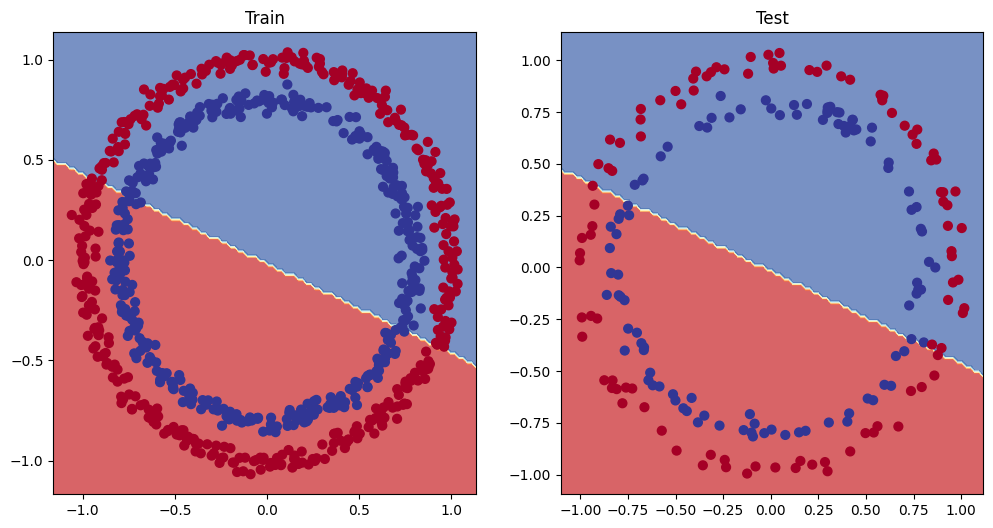

In [ ]:
# Plot decision boundary of the model
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

# Obviously, it didn't work. But is this actually useless?
- Many times in ML, it is best to start off with smaller model and test it out.
- This checks if the model is actually learning, anywhere.
- It works extremly well for the linear regression... WHich means:

We need a different approach...... One that works for something non-Linear...

 Of course it didn't work, we gave it only straight lines and expexted it to build a circle.



# The missing piece => Non-linearality

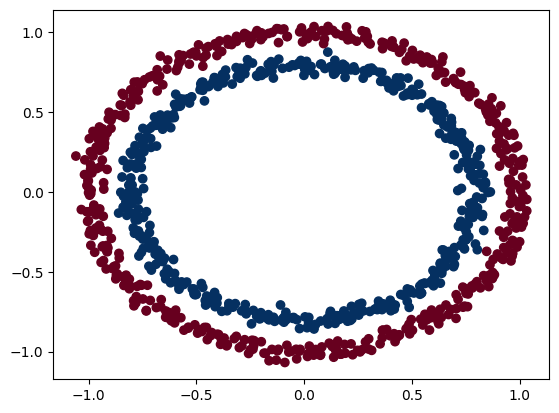

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Make and plot data
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000

X, y = make_circles(n_samples=1000,
    noise=0.03,
    random_state=42,
)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu);

In [ ]:
import torch
import numpy as np
from sklearn.model_selection import train_test_split

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

# SPlit to sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train[:5], y_train[:5]

(tensor([[ 0.6579, -0.4651],
         [ 0.6319, -0.7347],
         [-1.0086, -0.1240],
         [-0.9666, -0.2256],
         [-0.1666,  0.7994]]),
 tensor([1., 0., 0., 0., 1.]))

In [ ]:
# Build a model with Non-Linear functions
class CircleModelV2(nn.Module):
  def __init__(self):
    super().__init__()
    self.layer_1 = nn.Linear(in_features=2, out_features=10)
    self.layer_2 = nn.Linear(in_features=10, out_features=10)
    self.layer_3  = nn.Linear(in_features=10, out_features=1)
    self.relu = nn.ReLU() # A Non-Linear function


  def forward(self, x):
    return self.layer_3(self.layer_2(self.relu((self.layer_1(x)))))

model_3 = CircleModelV2().to(device)
model_3



CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model_3.parameters(), lr=0.1)

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

# Loop through data
epochs = 1000

for epoch in range(epochs):
  model_3.train()

  # 1. Forward pass
  y_logits = model_3(X_train).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))

  # 2. Loss Calc
  loss = loss_fn(y_logits, y_train)
  acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

  # 3. Optimizer zero grad
  optimizer.zero_grad()

  # 4. Loss backward
  loss.backward()

  # 5. Optimizer step
  optimizer.step()

# Testing
  model_3.eval()
  with torch.inference_mode():
    test_logits = model_3(X_test).squeeze()
    test_pred = torch.round(torch.sigmoid(test_logits))
    test_loss = loss_fn(test_logits, y_test)
    test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

  if epoch % 100 == 0:
    print(f"Epoch:{epoch}, Loss:{loss:.5f}, Accuracy:{acc:.2f}%, Test Loss:{test_loss:.5f}, Test Acc:{test_acc:.2f}%")


Epoch:0, Loss:0.69441, Accuracy:50.00%, Test Loss:0.69412, Test Acc:50.00%
Epoch:100, Loss:0.68984, Accuracy:52.38%, Test Loss:0.68935, Test Acc:51.00%
Epoch:200, Loss:0.68707, Accuracy:58.25%, Test Loss:0.68601, Test Acc:59.00%
Epoch:300, Loss:0.68338, Accuracy:53.87%, Test Loss:0.68177, Test Acc:58.00%
Epoch:400, Loss:0.67826, Accuracy:53.87%, Test Loss:0.67591, Test Acc:57.00%
Epoch:500, Loss:0.67058, Accuracy:53.25%, Test Loss:0.66753, Test Acc:58.00%
Epoch:600, Loss:0.65828, Accuracy:59.13%, Test Loss:0.65466, Test Acc:59.00%
Epoch:700, Loss:0.63517, Accuracy:71.75%, Test Loss:0.63262, Test Acc:75.00%
Epoch:800, Loss:0.59027, Accuracy:85.88%, Test Loss:0.59330, Test Acc:87.00%
Epoch:900, Loss:0.51050, Accuracy:94.12%, Test Loss:0.52613, Test Acc:90.50%


In [ ]:
model_3.eval()
with torch.inference_mode():
  y_logits = model_3(X_test).squeeze()
  y_pred = torch.round(torch.sigmoid(y_logits))
y_pred[:10], y_test[:10]

(tensor([1., 1., 1., 0., 1., 1., 0., 0., 1., 1.], device='cuda:0'),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0'))

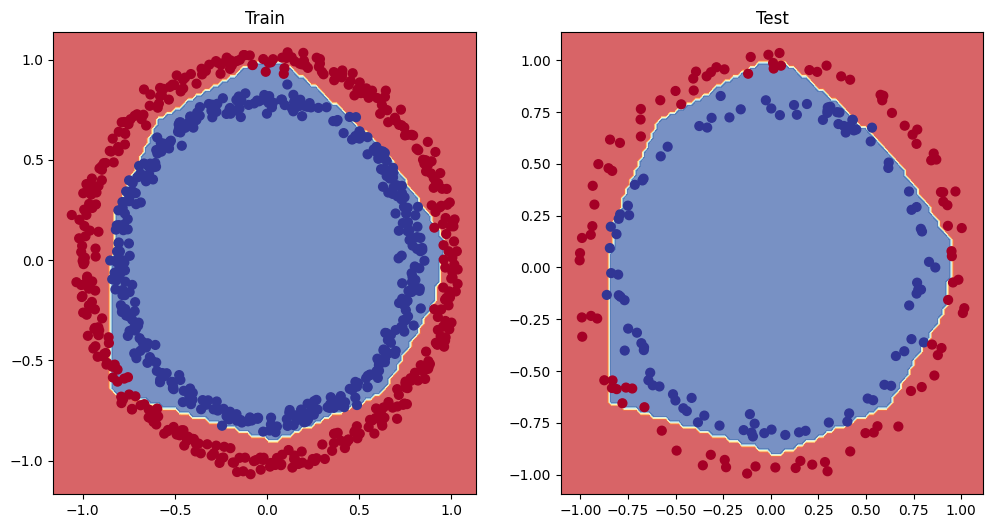

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_3, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_3, X_test, y_test)

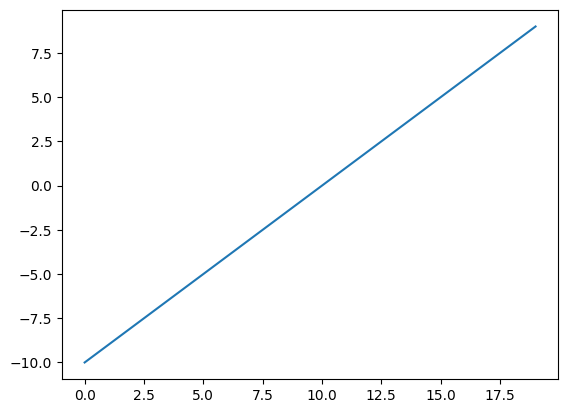

In [ ]:
A = torch.arange(-10, 10, 1, dtype=torch.float32)
plt.plot(A)

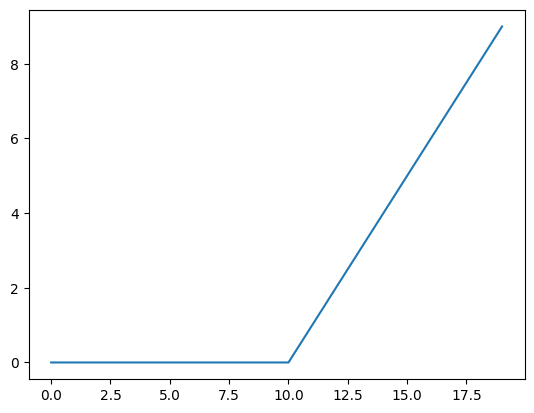

In [ ]:
# Create ReLU function by hand
def relu(x):
  return torch.maximum(torch.tensor(0), x) # inputs must be tensors

# Pass toy tensor through ReLU function
relu(A)
plt.plot(relu(A))

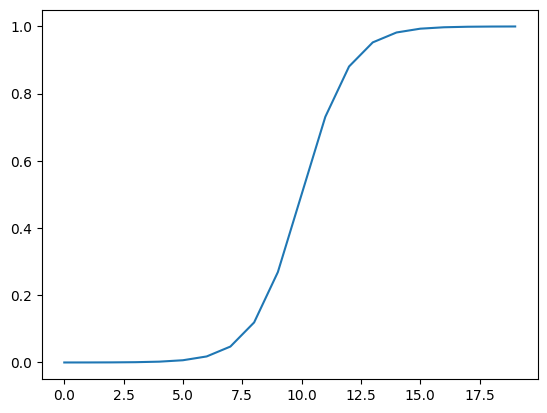

In [ ]:
# Create a custom sigmoid function
def sigmoid(x):
  return 1 / (1 + torch.exp(-x))

# Test custom sigmoid on toy tensor
sigmoid(A)
plt.plot(sigmoid(A))

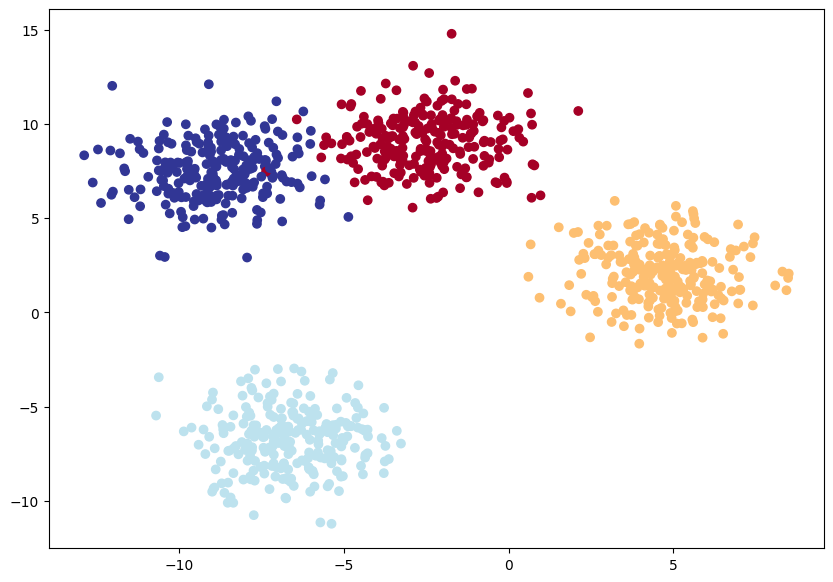

In [ ]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Set the hyperparameters for data creation
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

# 1. Create multiclass data
X_blob, y_blob = make_blobs(n_samples=1000, n_features=NUM_FEATURES, centers = NUM_CLASSES, cluster_std = 1.5, random_state=RANDOM_SEED)

# 2. Turn data into tensors
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

# 3. Split data into training and test sets
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(X_blob, y_blob, test_size=0.2, random_state=RANDOM_SEED)

# 4. Plot data (Visualize!)
plt.figure(figsize=(10, 7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu)

Building a multiclass classification model in Pytorch.
In order to evavluate and train and test our model, we have to convert logits to prediction probabilities.
Logits(raw output) => pred probs (use torch.softmax such that sum(x1..xn = 1)) => pred labels(take argmax of the prediction probablilties.)

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"

class BlobModel(nn.Module):
  def __init__(self, input_features, output_features, hidden_units = 8):
    super().__init__()
    self.linear_layer_stack = nn.Sequential(
        nn.Linear(in_features=input_features, out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units, out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units, out_features=output_features))
  def forward(self, x):
    return self.linear_layer_stack(x)

# Create an instance of a model and send it to the target device.
model_4 = BlobModel(input_features=2, output_features=4, hidden_units=8).to(device)

# Create a loss function
loss_fn = nn.CrossEntropyLoss()

# Create optimizer function
optimizer = torch.optim.SGD(params = model_4.parameters(), lr = 0.1)


# Let's get some raw outputs of our model (logits)
model_4.eval()
with torch.inference_mode():
  y_logits = model_4(X_blob_test.to(device))


# Convert our models logit outputs to prediction probabilities
y_pred_probs = torch.softmax(y_logits, dim= 1)

# Creating a testing and training loop
torch.manual_seed(43)
torch.cuda.manual_seed(43)
epoch = 100
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

# Loop through Data
epochs = 100
for epoch in range (epochs):
  model_4.train()
  y_logits = model_4(X_blob_train)
  y_pred = torch.softmax(y_logits, dim = 1).argmax(dim=1)

  loss = loss_fn(y_logits, y_blob_train)
  acc = accuracy_fn(y_true=y_blob_train, y_pred = y_pred)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  # Testing
  model_4.eval()
  with torch.inference_mode():
    test_logits = model_4(X_blob_test.to(device))
    test_preds = torch.softmax(test_logits, dim=1).argmax(dim=1)
    test_loss = loss_fn(test_logits, y_blob_test)
    test_acc = accuracy_fn(y_true=y_blob_test, y_pred=test_preds) # Corrected y_pred to test_preds

  # Print out what's happening:
    if epoch % 10  == 0:
      print(f"Epoch = {epoch} | Loss = {loss:.4f} | Acc: {acc:.2f} %| Test Loss {test_loss:.4f}, Test Acc: {test_acc:.2f} % ")



Epoch = 0 | Loss = 1.1588 | Acc: 40.38 %| Test Loss 1.0755, Test Acc: 48.00 % 
Epoch = 10 | Loss = 0.6448 | Acc: 96.75 %| Test Loss 0.6607, Test Acc: 97.50 % 
Epoch = 20 | Loss = 0.4254 | Acc: 98.50 %| Test Loss 0.4307, Test Acc: 100.00 % 
Epoch = 30 | Loss = 0.2529 | Acc: 99.12 %| Test Loss 0.2451, Test Acc: 99.50 % 
Epoch = 40 | Loss = 0.1123 | Acc: 99.25 %| Test Loss 0.1023, Test Acc: 99.50 % 
Epoch = 50 | Loss = 0.0663 | Acc: 99.25 %| Test Loss 0.0585, Test Acc: 99.50 % 
Epoch = 60 | Loss = 0.0507 | Acc: 99.25 %| Test Loss 0.0429, Test Acc: 99.50 % 
Epoch = 70 | Loss = 0.0430 | Acc: 99.25 %| Test Loss 0.0349, Test Acc: 99.50 % 
Epoch = 80 | Loss = 0.0384 | Acc: 99.25 %| Test Loss 0.0299, Test Acc: 99.50 % 
Epoch = 90 | Loss = 0.0352 | Acc: 99.25 %| Test Loss 0.0266, Test Acc: 99.50 % 


### What does `y_true=y_blob_train` mean?

In machine learning, `y_true` represents the **ground truth** or **actual labels** of your data. When you see `y_true=y_blob_train`, it means that `y_blob_train` holds the correct labels for the corresponding input data `X_blob_train`.

During training, the model's predictions are compared to these `y_true` labels to calculate how well the model is performing. The goal is to minimize the difference between the predicted labels and the true labels.

In [ ]:
model_4.eval()
with torch.inference_mode():
  y_logits = model_4(X_blob_test)

  y_logits[:10]
  y_pred_probs = torch.softmax(y_logits, dim=1)


In [ ]:
y_pred_probs = torch.softmax(y_logits, dim=1)


In [ ]:
# Go from logits -> Prediction probablilites
Y_preds = torch.argmax(y_pred_probs, dim=1)
y_pred[:10]

tensor([1, 0, 2, 2, 0, 0, 0, 1, 3, 0], device='cuda:0')

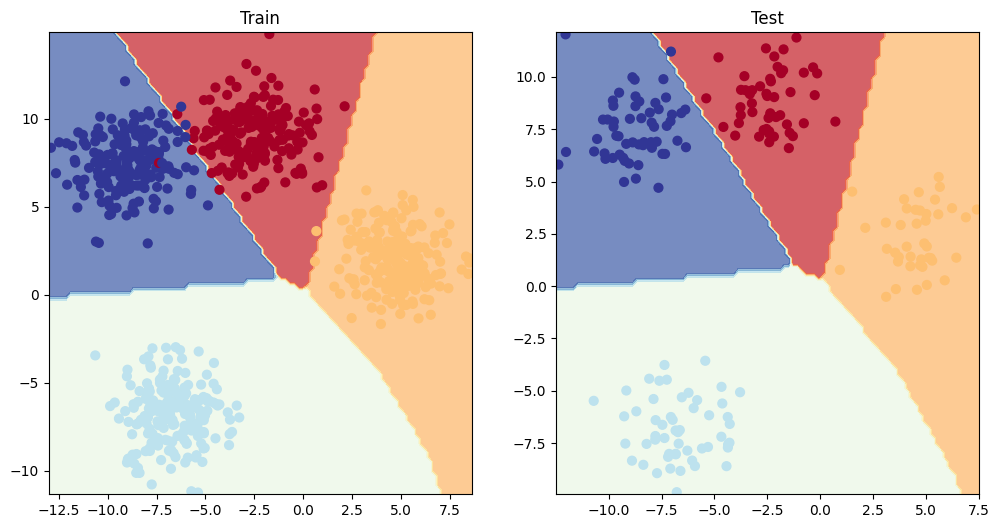

In [ ]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)
plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)

# More classification evaluation metrics
So far we've only covered a couple of ways of evaluating a classification model (accuracy, loss and visualizing predictions).

These are some of the most common methods you'll come across and are a good starting point.

However, you may want to evaluate your classification model using more metrics such as the following:

- Metric name/Evaluation method	Defintion	Code
Accuracy	Out of 100 predictions, how many does your model get correct? E.g. 95% accuracy means it gets 95/100 predictions correct.	torchmetrics.Accuracy() or sklearn.metrics.accuracy_score()



- Precision	Proportion of true positives over total number of samples. Higher precision leads to less false positives (model predicts 1 when it should've been 0).	torchmetrics.Precision() or sklearn.metrics.precision_score()
Recall	Proportion of true positives over total number of true positives and false negatives (model predicts 0 when it should've been 1). Higher recall leads to less false negatives.	torchmetrics.Recall() or sklearn.metrics.recall_score()


- F1-score	Combines precision and recall into one metric. 1 is best, 0 is worst.	torchmetrics.F1Score() or sklearn.metrics.f1_score()
Confusion matrix	Compares the predicted values with the true values in a tabular way, if 100% correct, all values in the matrix will be top left to bottom right (diagnol line).	torchmetrics.ConfusionMatrix or sklearn.metrics.plot_confusion_matrix()


- Classification report	Collection of some of the main classification metrics such as precision, recall and f1-score.	sklearn.metrics.classification_report()
Scikit-Learn (a popular and world-class machine learning library) has many implementations of the above metrics and you're looking for a PyTorch-like version, check out TorchMetrics, especially the TorchMetrics classification section.



## With that we are done with this part!
The main takeaway is that certain situtions (almost always in real life) requires algorithms beyond a stright line.

- The continuation lies in the github repo, where we are going to work with pytorch computer_vision.